# El enfoque del sustituto aprendido frente a la planta: lo que un puntaje de muestra de prueba no dice

**Pregunta:** El estado del arte juzga un sustituto aprendido de un modelo de conminución por su error frente a ese modelo; ¿qué dice el mismo sustituto de los diez muestreos reales del HP500, y avisa el autoencoder cuando no sabe?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** el notebook 02 de este tema y el notebook 01 del tema 05-real-surveys
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook usted puede:

- enunciar qué afirma el estado del arte de sustitutos aprendidos y cómo se valida;
- aplicar ese mismo enfoque, el sustituto propio del producto, a los diez muestreos y compararlo con la medición;
- encontrar el rango de entradas donde la red deja de ser un modelo del motor, y mostrar qué devuelve fuera de él;
- decir si el autoencoder del producto avisa en ese punto, y qué implica eso para cómo puede usarse el sustituto.

## Preparación

Las mismas cuatro bibliotecas del resto del tema.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.27.0 jsonschema==4.26.0
```

Las importaciones agregan el lector de muestreos y el punto de operación de la vía calibrada del tema 05, el puntuador de anomalías y los rangos de la barrida del dominio de entrenamiento.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'onnxruntime', 'jsonschema'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from dataclasses import replace

from pipeline.hp500.surveys import read_surveys
from pipeline.model import sweep
from pipeline.model.bundles import surrogate_predict, anomaly_score
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.stages.evaluate import _r2_mape
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.27.0
jsonschema 4.26.0


## Datos

Los diez muestreos del HP500, con los resultados calibrados del motor en ellos, y los dos modelos publicados. El sustituto y el autoencoder son modelos publicados de ChancaDEM, entrenados por el propio pipeline con una barrida de hipercubo latino del motor y versionados con sus contratos (`surrogate-model`, `anomaly-model`). Clase de licencia: MIT, como el resto del repositorio; los datos de entrenamiento son sintéticos, sorteados del motor. Las filas de muestreos son de Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919, clase de licencia CC BY 4.0. Archivos leídos: `data/examples/hp500-surveys.csv`, `data/derived/hp500/backbone.json` y los modelos bajo `data/derived/models/`.

La celda lee los muestreos y la columna vertebral versionada, y fija la carpeta de modelos.

In [2]:
# Lea los muestreos y la columna vertebral versionada, y fije la carpeta de modelos
surveys = read_surveys().accepted
backbone_doc = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))
models_dir = ROOT / "data" / "derived" / "models"
measured = np.array([s.feed_tph for s in surveys])
print("muestreos:", len(surveys), "| rango de tonelaje medido [t/h]:", measured.min(), measured.max())

muestreos: 10 | rango de tonelaje medido [t/h]: 813.0 1639.0


## Método

**Qué se corre.** El sustituto del producto es el enfoque de sustituto aprendido en el sentido de la sección siguiente: una red pequeña que emula un modelo fenomenológico de conminución. El método de este notebook es el del producto, el motor y su red publicada, corridos en los puntos de operación de los diez muestreos. La celda construye el punto de operación de cada muestreo en la vía calibrada, y luego su contraparte de la vía sintética, las mismas entradas con la calibración apagada, que es el punto que la red puede representar porque no tiene una entrada de calibración. Imprime la competencia del mineral A*b de la vía calibrada junto al rango con que se entrenó la red.

In [3]:
# Construya el punto de operación calibrado de cada muestreo y compare sus entradas con el dominio de entrenamiento
calibrated = [operating_from_survey(s.css_mm, s.f80_mm) for s in surveys]
domain = sweep.RANGES["cone-sec"]
print("A*b del mineral de la vía calibrada:", calibrated[0].ore_axb, "| rango de entrenamiento:", domain["ore_axb"])
outside = {s.survey: [k for k in domain if not domain[k][0] <= getattr(o, k) <= domain[k][1]] for s, o in zip(surveys, calibrated)}
print("entradas fuera del rango de entrenamiento, por muestreo:")
for survey, names in outside.items():
    print(f"  {survey:2d}: {names}")
alarms = [anomaly_score(evaluate(o), models_dir)[0]["is_anomaly"] for o in calibrated]
print("alarmas del autoencoder sobre los resultados calibrados de los diez muestreos:", sum(alarms), "de 10")

A*b del mineral de la vía calibrada: 677.3 | rango de entrenamiento: (30, 110)
entradas fuera del rango de entrenamiento, por muestreo:
   1: ['ore_axb']
   2: ['ore_axb']
   3: ['feed_x63_mm', 'ore_axb']
   4: ['ore_axb']
   5: ['feed_x63_mm', 'ore_axb']
   6: ['ore_axb']
   7: ['ore_axb']
   8: ['ore_axb']
   9: ['ore_axb']
  10: ['ore_axb']
alarmas del autoencoder sobre los resultados calibrados de los diez muestreos: 8 de 10


## Estado del arte

**El protocolo, corrido.** El puntaje de muestra de prueba de esa literatura se corre aquí sobre la red del producto con una muestra independiente pequeña, 60 puntos por máquina con la semilla de la evaluación, para que el notebook muestre qué es el puntaje antes de preguntar qué le falta. La celda puntúa el P80 y la capacidad del sustituto publicado frente al motor en los puntos que el motor acepta.

In [4]:
# Corra el protocolo de muestra de prueba: R2 y MAPE de P80 y de la capacidad en una muestra independiente pequeña
test_points = sweep.label(sweep.draw(60, 67890))
answers = [surrogate_predict(r.op, models_dir)[0] for r in test_points]
for key, field in (("p80_mm", "p80"), ("throughput_tph", "throughput_tph")):
    truth_values = np.array([getattr(r, field) for r in test_points])
    network_values = np.array([a[key] for a in answers])
    r2, error = _r2_mape(network_values, truth_values)
    print(f"{key:15s} puntos de prueba {len(test_points)}  R2 {r2:.4f}  MAPE {error:.2f} %")

p80_mm          puntos de prueba 276  R2 0.9971  MAPE 4.22 %
throughput_tph  puntos de prueba 276  R2 0.9984  MAPE 5.05 %


**La fuente.** Koh et al. (2021; https://doi.org/10.1016/j.mineng.2021.107026) entrenan una red neuronal profunda para aproximar los modelos fenomenológicos de un circuito de conminución, con el fin de correr simulaciones de circuito más rápido. La ficha de marco del producto para este tema registra la misma lectura de ese trabajo: un sustituto de un modelo y no de datos de planta, validado frente al modelo que emula, fuera de línea, sin informar una comparación industrial con datos retenidos ni una incertidumbre; la ficha registra además una aceleración de unas tres mil veces y cifras de error muy bajo uno por ciento, que son cifras de ese artículo y no se reproducen aquí, porque ni su circuito ni su código están en este repositorio. Lo que se puede correr es el enfoque, sobre el propio motor del producto.

Su protocolo es un puntaje de muestra de prueba: una muestra retenida de la misma distribución que los datos de entrenamiento, comparada con el profesor. El notebook 02 lo corrió: R cuadrado entre 0,979 y 0,998. La pregunta aquí es la que ese protocolo no puede hacer: ¿qué dice el sustituto de una planta? La celda lo corre en los diez muestreos de dos maneras. La primera es la honesta que la red puede hacer: el punto de operación con la calibración apagada y el mineral en el borde de su rango de entrenamiento, A*b = 100, que es lo que tendría un usuario que se mantiene dentro del dominio. La segunda es el punto tal como lo tiene la vía calibrada, con A*b = 677, muy fuera del rango. Para cada una imprime el error absoluto medio del tonelaje frente a la medición, con el del profesor, el motor sintético, y el de la columna vertebral calibrada como referencia.

In [5]:
# Error absoluto medio de tonelaje frente a la medición: la red dentro y fuera de su dominio, su profesor y la columna vertebral calibrada
inside = [replace(o, calibrated=False, ore_axb=100.0, ore_wi=sweep.wi_of_axb(100.0)) for o in calibrated]
outside_domain = [replace(o, calibrated=False) for o in calibrated]
network_inside = np.array([surrogate_predict(o, models_dir)[0]["throughput_tph"] for o in inside])
network_outside = np.array([surrogate_predict(o, models_dir)[0]["throughput_tph"] for o in outside_domain])
teacher_inside = np.array([evaluate(o).throughput_tph for o in inside])
backbone_tph = np.array([s["backbone"]["throughput_tph"] for s in backbone_doc["surveys"]])


def mape(estimate):
    return float(np.mean(np.abs((estimate - measured) / measured)) * 100)


for name, values in (("sustituto, mineral en el borde del dominio (A*b = 100)", network_inside), ("su profesor, el motor sintético (A*b = 100)", teacher_inside), ("columna vertebral calibrada (la vía calibrada del motor)", backbone_tph), ("sustituto con el mineral de la vía calibrada (A*b = 677)", network_outside)):
    print(f"{name:62s} MAPE {mape(values):7.2f} %")

sustituto, mineral en el borde del dominio (A*b = 100)         MAPE   24.78 %
su profesor, el motor sintético (A*b = 100)                    MAPE   21.72 %
columna vertebral calibrada (la vía calibrada del motor)       MAPE   11.55 %
sustituto con el mineral de la vía calibrada (A*b = 677)       MAPE  118.20 %


La figura dibuja las cuatro estimaciones frente al tonelaje medido, muestreo por muestreo, para que las brechas se vean una por una.

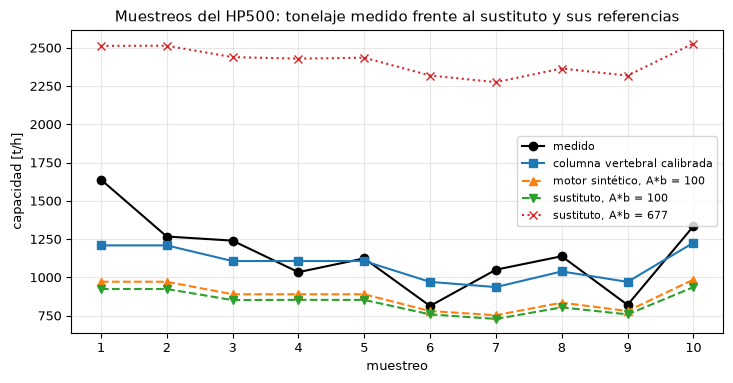

In [6]:
# Grafique el tonelaje medido y las cuatro estimaciones muestreo por muestreo
fig, ax = plt.subplots()
numbers = [s.survey for s in surveys]
ax.plot(numbers, measured, "ko-", label="medido")
ax.plot(numbers, backbone_tph, "s-", label="columna vertebral calibrada")
ax.plot(numbers, teacher_inside, "^--", label="motor sintético, A*b = 100")
ax.plot(numbers, network_inside, "v--", label="sustituto, A*b = 100")
ax.plot(numbers, network_outside, "x:", label="sustituto, A*b = 677")
ax.set_xticks(numbers)
ax.set_xlabel("muestreo")
ax.set_ylabel("capacidad [t/h]")
ax.set_title("Muestreos del HP500: tonelaje medido frente al sustituto y sus referencias")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Cuatro de las cinco líneas van juntas aproximadamente al nivel de la planta, a unos cientos de t/h. La quinta no: el sustituto con el mineral de la vía calibrada devuelve más de 2300 t/h en cada muestreo, más del doble de las mediciones. De las líneas dentro del dominio, el sustituto y su profesor quedan bajo la medición y la columna vertebral calibrada, que se ajustó a los muestreos, queda más cerca. El error del sustituto frente a la planta, 24,8 por ciento, es el 21,7 por ciento del profesor más los 3 puntos propios de la red: la red hereda el error del profesor, sea cual sea su R cuadrado frente a él. La figura muestra que la brecha con la planta es una propiedad del profesor, no del aprendizaje.

**Dónde se rompe la red.** La quinta línea no es un problema de calibración; es una extrapolación. El rango de entrenamiento de la competencia del mineral es 30 a 110, y A*b = 677 es seis veces su borde superior. El motor lo resuelve, porque la relación t10 se satura en su tope de 0,44 y devuelve un resultado finito y ordinario; la red no tiene ese tope. La celda barre la competencia del mineral de S01 desde dentro del rango hasta muy fuera de él e imprime, para la red y para el motor, el P80 y la potencia, junto con el veredicto del autoencoder sobre el resultado del motor en cada punto.

In [7]:
# Barra la competencia del mineral de S01 desde dentro del rango de entrenamiento hasta muy fuera de él
from pipeline.model.crusher import Operating

base = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
print("A*b   P80 red    P80 motor   kW red       kW motor    alarma del autoencoder sobre el resultado del motor")
for axb in (30, 55, 110, 200, 400, 677):
    point = replace(base, ore_axb=float(axb), ore_wi=sweep.wi_of_axb(axb))
    answer = surrogate_predict(point, models_dir)[0]
    engine = evaluate(point)
    alarm = anomaly_score(engine, models_dir)[0]["is_anomaly"]
    print(f"{axb:4d} {answer['p80_mm']:10.2f} {engine.p80:11.2f} {answer['power_kw']:12.1f} {engine.power_kw:11.1f}   {alarm}")

A*b   P80 red    P80 motor   kW red       kW motor    alarma del autoencoder sobre el resultado del motor
  30      28.99       29.72        305.9       309.0   False
  55      27.50       27.70        275.6       284.3   False
 110      26.70       26.85        169.3       188.1   False
 200      21.00       26.85         -8.1       169.1   False
 400      11.96       26.85       -237.4       169.1   False
 677       5.75       26.85       -548.5       169.1   False


Dentro del rango los dos coinciden. Pasado 110 el P80 de la red sigue bajando, de 26,7 mm a 5,75 mm, porque extrapola la tendencia a la baja que aprendió, mientras el del motor se queda en 26,85 mm; y su potencia pasa por cero, a -8 kW con A*b = 200 y -548 kW con 677, una potencia negativa que ninguna máquina tiene, mientras la del motor se satura en 169 kW. La última columna es el hallazgo: el autoencoder no da alarma en ninguno de estos puntos, porque puntúa el resultado del motor, y el resultado del motor con A*b = 677 es uno ordinario. La guarda que el producto describe como la comprobación de fuera de distribución del sustituto es ciega a una entrada que está muy fuera del rango de entrenamiento y que el motor satura, que es exactamente el caso de los diez muestreos reales. La figura grafica la potencia.

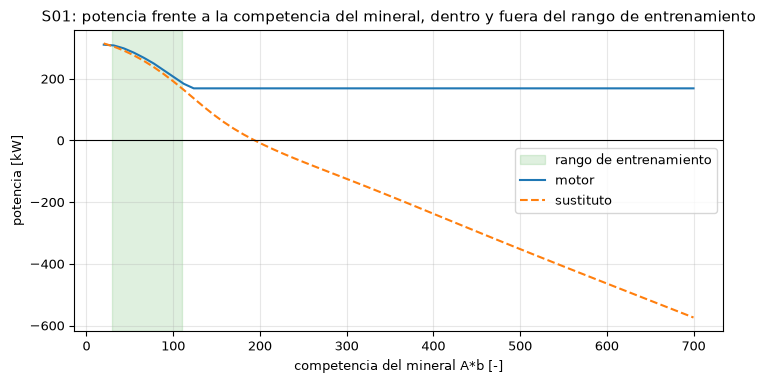

In [8]:
# Grafique la potencia de la red y del motor contra la competencia del mineral, con el rango de entrenamiento sombreado
grid = np.linspace(20, 700, 60)
points = [replace(base, ore_axb=float(a), ore_wi=sweep.wi_of_axb(a)) for a in grid]
fig, ax = plt.subplots()
ax.axvspan(*domain["ore_axb"], color="tab:green", alpha=0.15, label="rango de entrenamiento")
ax.plot(grid, [evaluate(p).power_kw for p in points], label="motor")
ax.plot(grid, [surrogate_predict(p, models_dir)[0]["power_kw"] for p in points], "--", label="sustituto")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("competencia del mineral A*b [-]")
ax.set_ylabel("potencia [kW]")
ax.set_title("S01: potencia frente a la competencia del mineral, dentro y fuera del rango de entrenamiento")
ax.legend()
fig.tight_layout()
plt.show()

Las dos curvas coinciden en la banda verde y se separan en su borde derecho: la línea de la red cae bajo cero mientras la del motor se aplana. La figura muestra el modo de falla de un sustituto aprendido en una imagen, una extrapolación sin restricciones, y la compuerta de envolvente del propio motor tampoco lo atrapa en A*b, que la compuerta no prueba. Lo que se sigue para el uso es simple: la red puede responder dentro de la caja de sus rangos de entrenamiento y el producto debe comprobar la caja sobre la entrada, lo que una prueba de rango hace exactamente y gratis, en vez de apoyarse en un detector de la salida.

## Resultados

**Respuesta:** el enfoque del sustituto es preciso frente a su profesor, y dice de la planta lo que dice el profesor: en una muestra independiente pequeña de 276 puntos su puntaje de muestra de prueba es R cuadrado 0,9971 para P80 y 0,9984 para la capacidad. En los diez muestreos, con el mineral en el borde del rango de entrenamiento, el error absoluto medio de tonelaje del sustituto frente a la medición es 24,78 por ciento, el del motor sintético 21,72 y el de la columna vertebral calibrada 11,55: la red hereda el error del profesor y agrega unos 3 puntos. Alimentada con el mineral de la vía calibrada, A*b = 677 frente a un rango de entrenamiento de 30 a 110, devuelve más de 2300 t/h en cada muestreo (118,21 por ciento de error medio) y una potencia de cerca de -575 kW. El autoencoder no da alarma en la barrida de A*b de S01, en ninguno de 6 puntos, porque el resultado del motor allí es ordinario; con los resultados calibrados de los diez muestreos alarma en 8 de 10.

La primera figura muestra que la brecha con la planta es la del profesor, la segunda la falla pasado el rango. Un validador concluiría que un R cuadrado de muestra de prueba valida la emulación y nada más, que el sustituto del producto debe guardarse sobre su rango de entrada y no solo con un detector de la salida, y que la vía real, calibrada y medida, es la evidencia que aporta a la planta el motor y no la red. Son las conclusiones de una medición sobre la red propia del producto; las cifras del artículo para su propio circuito no se prueban aquí.

## Resumen

El enfoque del sustituto aprendido se valida frente al modelo que emula, y la red del producto cumple esa vara; lo que dice de la planta es lo que dice su profesor, algo peor. La red extrapola sin límite fuera de su caja de entrenamiento, el autoencoder no lo ve cuando el motor se satura, y una prueba de rango sobre la entrada sí lo vería. Para la planta, la vía calibrada del motor y su validación con datos retenidos (tema 06) son la evidencia, y el sustituto es una aproximación rápida para usar dentro de su caja.

## Referencias

- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919